## install the packages

In [5]:
! pip install scikit-learn==1.6.1 streamlit pandas numpy matplotlib seaborn plotly joblib

## import libraris

In [6]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sklearn
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', 50)
print('scikit-learn version:', sklearn.__version__)

scikit-learn version: 1.6.1


## Load the data

In [8]:
df = pd.read_csv('vehicles.csv')
df.head()

C:\Users\gaswe\AppData\Local\Temp\ipykernel_3032\53803598.py:1: DtypeWarning: Columns (4,32,40) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('vehicles.csv')


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,image_url,description,county,state,lat,long,posting_date,seller_type,title,updated_date,address_street,address_city,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
0,7994372850,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,27999,2022.0,ford,explorer st,excellent,6 cylinders,gas,99179.0,clean,automatic,1FM5K8GCXNGA77516,4wd,NaN,SUV,grey,https://images.craigslist.org/00N0N_aBzbdTBI4c...,⭐ Autorace ⭐ 🏷️ STOCK #: 1726 📞 CALL OR TEXT: ...,NaN,ca,37.371435,-122.047863,2026-11-02T19:24:16-0800,dealer,2022 Ford Explorer ST,NaN,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00N0N_aBzbdTBI4c...,0,0,0,NaN,NaN
1,7994372787,https://sfbay.craigslist.org/cto/d/mill-valley...,SF bay area,https://sfbay.craigslist.org,2200,1969.0,volkswagen,bug,fair,4 cylinders,gas,90000.0,clean,manual,NaN,rwd,NaN,other,green,https://images.craigslist.org/00n0n_gNzbApFpKG...,I am selling a 1969Vw Bug all original. This i...,NaN,ca,37.906000,-122.545000,2026-11-02T19:23:52-0800,owner,69 VW Bug All Original Runs and drives current...,NaN,NaN,Mill Valley,CA,94942,US,4,https://images.craigslist.org/00n0n_gNzbApFpKG...,0,0,0,NaN,NaN
2,7994372559,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,15999,2016.0,rover,sport,excellent,6 cylinders,gas,82896.0,clean,automatic,SALWR2VF6GA636931,4wd,NaN,SUV,white,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,⭐ Autorace ⭐ 🏷️ STOCK #: 1544 📞 CALL OR TEXT: ...,NaN,ca,37.371435,-122.047863,2026-11-02T19:22:44-0800,dealer,2016 Land Rover Range Rover Sport 3.0L V6 Supe...,2026-11-02T19:22:45-0800,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,0,0,0,NaN,NaN
3,7994372553,https://sfbay.craigslist.org/cto/d/napa-1974-c...,SF bay area,https://sfbay.craigslist.org,12000,1974.0,cadillac,eldorado convertible,good,8 cylinders,gas,89687.0,clean,automatic,NaN,fwd,NaN,convertible,blue,https://images.craigslist.org/00s0s_4aCpejyeUW...,Reluctantly posting this beauty for sale after...,NaN,ca,38.321878,-122.306027,2026-11-02T19:22:42-0800,owner,1974 Cadillac Eldorado Convertible,NaN,NaN,Napa,CA,94581,US,8,https://images.craigslist.org/00s0s_4aCpejyeUW...,0,0,0,NaN,NaN
4,7994372166,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,18999,2009.0,dodge,challenger lc srt8,excellent,8 cylinders,gas,81724.0,clean,automatic,2B3LJ74W39H549395,rwd,NaN,coupe,orange,https://images.craigslist.org/00T0T_4wec2Grzn3...,⭐ Autorace ⭐ 🏷️ STOCK #: 1621 📞 CALL OR TEXT: ...,NaN,ca,37.371435,-122.047863,2026-11-02T19:21:10-0800,dealer,2009 Dodge Challenger SRT8,NaN,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00T0T_4wec2Grzn3...,0,0,0,NaN,NaN


In [37]:
df.shape

(295451, 41)

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295451 entries, 0 to 295450
Data columns (total 41 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    295451 non-null  int64  
 1   url                   295451 non-null  object 
 2   region                295451 non-null  object 
 3   region_url            295451 non-null  object 
 4   price                 295451 non-null  object 
 5   year                  295425 non-null  float64
 6   manufacturer          284659 non-null  object 
 7   model                 292092 non-null  object 
 8   condition             159961 non-null  object 
 9   cylinders             215284 non-null  object 
 10  fuel                  294320 non-null  object 
 11  odometer              291415 non-null  float64
 12  title_status          288635 non-null  object 
 13  transmission          293895 non-null  object 
 14  VIN                   174332 non-null  object 
 15  

In [39]:
# missing values
df.isna().sum()

id                           0
url                          0
region                       0
region_url                   0
price                        0
year                        26
manufacturer             10792
model                     3359
condition               135490
cylinders                80167
fuel                      1131
odometer                  4036
title_status              6816
transmission              1556
VIN                     121119
drive                    70375
size                    295451
type                     15809
paint_color              74718
image_url                 3538
description                  6
county                  295451
state                        0
lat                        149
long                       149
posting_date                 0
seller_type                  0
title                        5
updated_date            179711
address_street          138758
address_city             14471
address_state            14471
address_

In [40]:
df.describe()

,id,year,odometer,size,county,lat,long,image_count,delivery_available,odometer_broken,odometer_rolled_over
count,2.954510e+05,295425.000000,2.914150e+05,0.0,0.0,295302.000000,295302.000000,295451.000000,295451.000000,295451.000000,295451.000000
mean,7.985641e+09,2012.771235,1.145619e+05,NaN,NaN,38.763646,-104.154990,17.094225,0.073288,0.006918,0.007761
std,5.481825e+06,11.580429,1.713099e+05,NaN,NaN,6.235714,19.691015,6.917641,0.260609,0.082888,0.087754
min,7.975321e+09,1900.000000,1.000000e+00,NaN,NaN,-46.156577,-159.719900,0.000000,0.000000,0.000000,0.000000
25%,7.980935e+09,2010.000000,6.762650e+04,NaN,NaN,34.061400,-121.465919,12.000000,0.000000,0.000000,0.000000
50%,7.985959e+09,2015.000000,1.075000e+05,NaN,NaN,38.851616,-110.958840,19.000000,0.000000,0.000000,0.000000
75%,7.990508e+09,2019.000000,1.473720e+05,NaN,NaN,43.595000,-84.455200,24.000000,0.000000,0.000000,0.000000
max,7.994391e+09,2027.000000,1.000000e+07,NaN,NaN,64.993698,178.877500,24.000000,1.000000,1.000000,1.000000


## Select the important columns

In [41]:
df_new = df.copy()

In [42]:
df_new = df_new[['price', 'year', 'odometer', 'manufacturer', 'condition', 'cylinders',
                 'fuel', 'title_status', 'transmission', 'drive', 'type', 'paint_color',
                 'state', 'seller_type', 'odometer_broken', 'odometer_rolled_over']].copy()
df_new.shape

(295451, 16)

## Clean data

In [43]:
# fix data types
df_new['price'] = pd.to_numeric(df_new['price'], errors='coerce')
df_new['cylinders'] = df_new['cylinders'].str.extract(r'(\d+)')[0].astype(float)
df_new[['price', 'cylinders']].dtypes

price        float64
cylinders    float64
dtype: object

In [44]:
# remove wrong values
print('Before:', df_new.shape)

df_new = df_new[df_new['price'].between(1000, 100000)]
df_new = df_new[df_new['year'].between(1990, 2025)]
df_new = df_new[df_new['odometer'].between(100, 400000)]
df_new = df_new[(df_new['odometer_broken'] == 0) & (df_new['odometer_rolled_over'] == 0)]
df_new = df_new.drop(columns=['odometer_broken', 'odometer_rolled_over'])

print('After :', df_new.shape)

Before: (295451, 16)
After : (257202, 14)


In [45]:
df_new[['price', 'year', 'odometer']].describe()

,price,year,odometer
count,257202.000000,257202.000000,257202.000000
mean,16977.843127,2014.224085,115075.925032
std,14508.457481,6.772845,58584.124539
min,1000.000000,1990.000000,100.000000
25%,6995.000000,2011.000000,74846.500000
50%,12988.000000,2015.000000,112000.000000
75%,21995.000000,2019.000000,150000.000000
max,100000.000000,2025.000000,400000.000000


In [46]:
print('Duplicate rows:', df_new.duplicated().sum())

df_new = df_new.drop_duplicates()

print('After removing duplicates:', df_new.shape)

Duplicate rows: 76470
After removing duplicates: (180732, 14)


In [47]:
print('Missing BEFORE:\n', df_new.isna().sum(), '\n')

# numeric -> median
df_new['cylinders'] = df_new['cylinders'].fillna(df_new['cylinders'].median())

# text -> 'unknown'
cat_cols = ['manufacturer', 'condition', 'fuel', 'title_status', 'transmission',
            'drive', 'type', 'paint_color', 'state', 'seller_type']
df_new[cat_cols] = df_new[cat_cols].fillna('unknown')

Missing BEFORE:
 price               0
year                0
odometer            0
manufacturer     5436
condition       72919
cylinders       47808
fuel              571
title_status     3730
transmission      586
drive           40359
type             8579
paint_color     42797
state               0
seller_type         0
dtype: int64 



In [48]:
df_new.isna().sum()

price           0
year            0
odometer        0
manufacturer    0
condition       0
cylinders       0
fuel            0
title_status    0
transmission    0
drive           0
type            0
paint_color     0
state           0
seller_type     0
dtype: int64

## Visualization

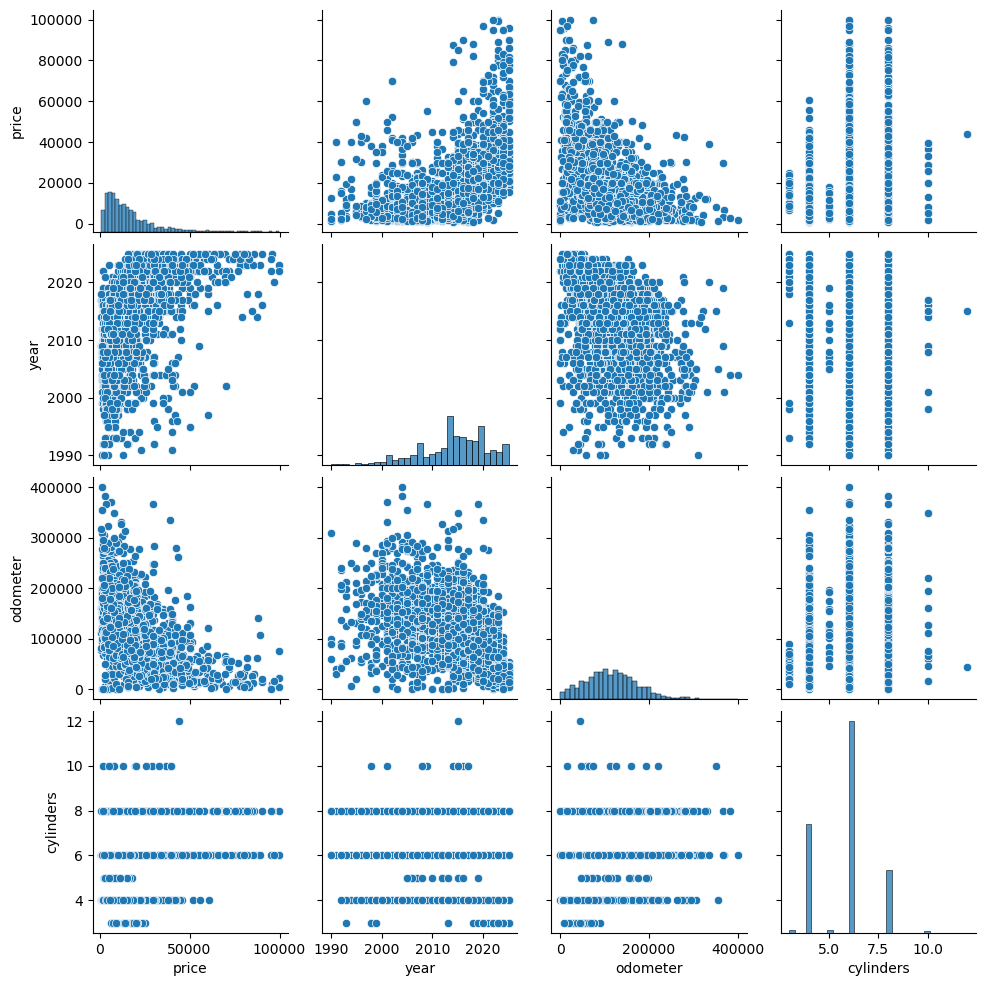

In [49]:
sns.pairplot(df_new[['price', 'year', 'odometer', 'cylinders']].sample(3000, random_state=42))
plt.show()

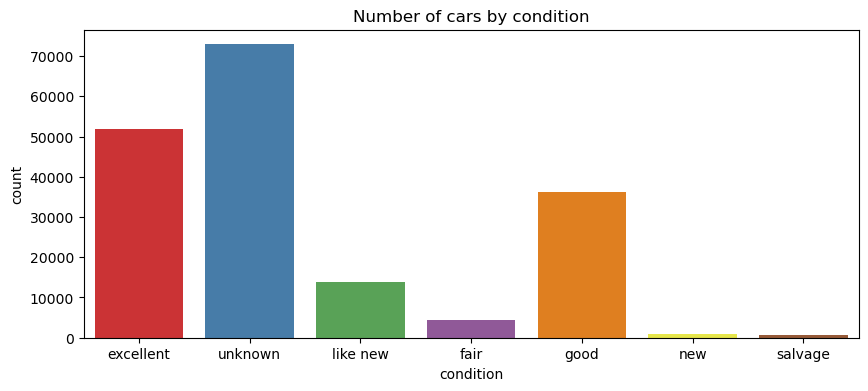

In [56]:
plt.figure(figsize=(10, 4))
sns.countplot(x='condition', data=df_new, hue='condition', palette='Set1', legend=False)
plt.title('Number of cars by condition')
plt.show()

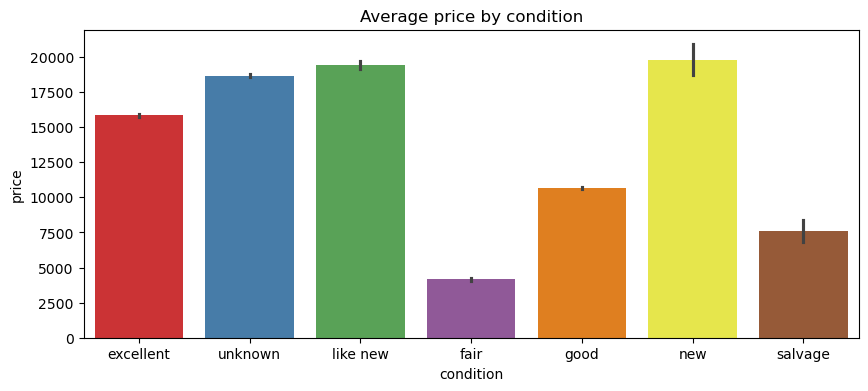

In [57]:
plt.figure(figsize=(10, 4))
sns.barplot(x='condition', y='price', data=df_new, hue='condition', palette='Set1', legend=False)
plt.title('Average price by condition')
plt.show()

## split input and output

In [58]:
X = df_new.drop('price', axis=1)
y = df_new['price']

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (180732, 13)
y shape: (180732,)


## encode the categorical columns (get_dummies)

In [59]:
cat_cols = ['manufacturer', 'condition', 'fuel', 'title_status', 'transmission',
            'drive', 'type', 'paint_color', 'state', 'seller_type']

X = pd.get_dummies(X, columns=cat_cols, drop_first=True)

print('X shape after get_dummies:', X.shape)
X.head()

X shape after get_dummies: (180732, 144)


,year,odometer,cylinders,manufacturer_alfa-romeo,manufacturer_aston-martin,manufacturer_audi,manufacturer_bmw,manufacturer_buick,manufacturer_cadillac,manufacturer_chevrolet,manufacturer_chrysler,manufacturer_datsun,manufacturer_dodge,manufacturer_ferrari,manufacturer_fiat,manufacturer_ford,manufacturer_gmc,manufacturer_harley-davidson,manufacturer_honda,manufacturer_hyundai,manufacturer_infiniti,manufacturer_jaguar,manufacturer_jeep,manufacturer_kia,manufacturer_land rover,...,state_nc,state_nd,state_ne,state_nh,state_nj,state_nm,state_nv,state_ny,state_oh,state_ok,state_or,state_pa,state_ri,state_sc,state_sd,state_tn,state_tx,state_ut,state_va,state_vt,state_wa,state_wi,state_wv,state_wy,seller_type_owner
0,2022.0,99179.0,6.0,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,2016.0,82896.0,6.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,2009.0,81724.0,8.0,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
5,2020.0,96104.0,6.0,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
6,2023.0,54131.0,4.0,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


## split data into train and test

In [60]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('x_train:', x_train.shape)
print('x_test :', x_test.shape)

x_train: (144585, 144)
x_test : (36147, 144)


## Apply scaling

In [61]:
sc = StandardScaler()
x_train_scaled = sc.fit_transform(x_train)
x_test_scaled = sc.transform(x_test)

print('x_train_scaled:', x_train_scaled.shape)
print('x_test_scaled :', x_test_scaled.shape)

x_train_scaled: (144585, 144)
x_test_scaled : (36147, 144)


## Apply the modeling

In [62]:
results = {}

def evaluate(name, model):
    pred_train = model.predict(x_train_scaled)
    pred_test = model.predict(x_test_scaled)
    results[name] = {
        'MAE_train': mean_absolute_error(y_train, pred_train),
        'MAE_test': mean_absolute_error(y_test, pred_test),
        'RMSE_test': np.sqrt(mean_squared_error(y_test, pred_test)),
        'R2_train': r2_score(y_train, pred_train),
        'R2_test': r2_score(y_test, pred_test),
    }
    print(name)
    for k, v in results[name].items():
        print(f'  {k:10s}: {v:,.3f}')

In [63]:
lr = LinearRegression()
lr.fit(x_train_scaled, y_train)
evaluate('Linear Regression', lr)

Linear Regression
  MAE_train : 5,511.754
  MAE_test  : 5,551.607
  RMSE_test : 8,493.850
  R2_train  : 0.622
  R2_test   : 0.622


In [64]:
dt = DecisionTreeRegressor(random_state=42)
dt.fit(x_train_scaled, y_train)
evaluate('Decision Tree', dt)

Decision Tree
  MAE_train : 30.517
  MAE_test  : 4,100.150
  RMSE_test : 7,513.252
  R2_train  : 1.000
  R2_test   : 0.704


In [65]:
rf = RandomForestRegressor(random_state=42, n_estimators=50, max_depth=20,
                           min_samples_leaf=3, n_jobs=-1)
rf.fit(x_train_scaled, y_train)
evaluate('Random Forest', rf)

Random Forest
  MAE_train : 2,655.807
  MAE_test  : 3,511.197
  RMSE_test : 5,908.827
  R2_train  : 0.897
  R2_test   : 0.817


## Evaluation - compare the models

In [66]:
results_df = pd.DataFrame(results).T.round(3)
results_df

,MAE_train,MAE_test,RMSE_test,R2_train,R2_test
Linear Regression,5511.754,5551.607,8493.850,0.622,0.622
Decision Tree,30.517,4100.150,7513.252,1.000,0.704
Random Forest,2655.807,3511.197,5908.827,0.897,0.817


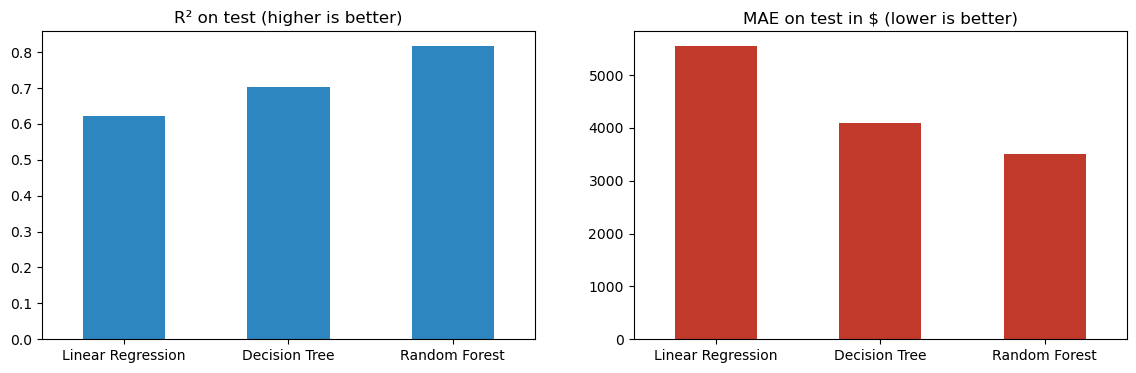

In [67]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
results_df['R2_test'].plot(kind='bar', ax=ax[0], color='#2e86c1', title='R² on test (higher is better)')
results_df['MAE_test'].plot(kind='bar', ax=ax[1], color='#c0392b', title='MAE on test in $ (lower is better)')
for a in ax:
    a.tick_params(axis='x', rotation=0)
plt.show()

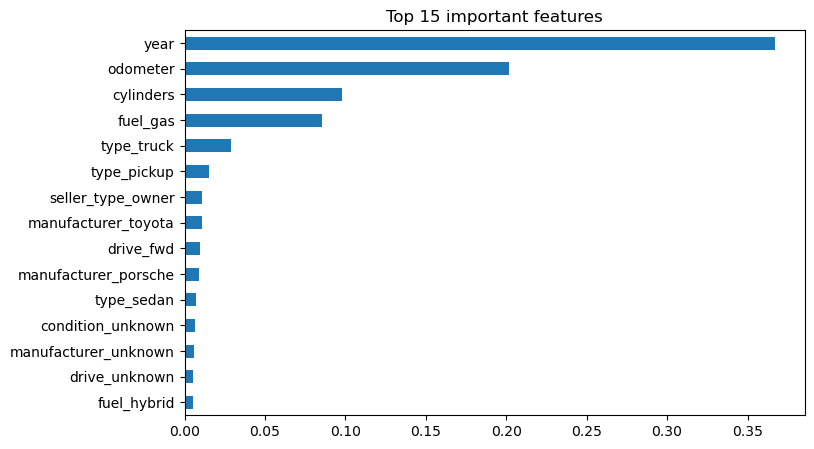

In [68]:
importances = pd.Series(rf.feature_importances_, index=x_train.columns).sort_values(ascending=False).head(15)
importances.plot(kind='barh', figsize=(8, 5), title='Top 15 important features').invert_yaxis()
plt.show()

## cross validation

In [71]:
x_cv = x_train_scaled[:50000]
y_cv = y_train[:50000]

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_validate(
    RandomForestRegressor(random_state=42, n_estimators=50, max_depth=20, min_samples_leaf=3, n_jobs=-1),
    x_cv, y_cv, cv=kfold,
    scoring=['r2', 'neg_mean_absolute_error'])

print('R2 for each fold :', scores['test_r2'].round(3))
print('Mean R2          :', scores['test_r2'].mean().round(3), '+/-', scores['test_r2'].std().round(3))
print('Mean MAE         :', (-scores['test_neg_mean_absolute_error']).mean().round(0))

R2 for each fold : [0.762 0.764 0.77  0.777 0.772]
Mean R2          : 0.769 +/- 0.005
Mean MAE         : 3926.0


## hyper parameter tuning

In [72]:
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None]
}

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42, min_samples_leaf=3, n_jobs=-1),
    param_grid, cv=3, scoring='r2')

grid_search.fit(x_cv[:30000], y_cv[:30000])

grid_search.best_params_

{'max_depth': None, 'n_estimators': 100}

In [73]:
pd.DataFrame(grid_search.cv_results_)[['params', 'mean_test_score', 'rank_test_score']].sort_values('rank_test_score')

,params,mean_test_score,rank_test_score
5,"{'max_depth': None, 'n_estimators': 100}",0.749169,1
3,"{'max_depth': 20, 'n_estimators': 100}",0.747871,2
4,"{'max_depth': None, 'n_estimators': 50}",0.747708,3
2,"{'max_depth': 20, 'n_estimators': 50}",0.746409,4
1,"{'max_depth': 10, 'n_estimators': 100}",0.720736,5
0,"{'max_depth': 10, 'n_estimators': 50}",0.720076,6


In [74]:
rf_best = RandomForestRegressor(random_state=42, n_estimators=100, max_depth=20,
                                min_samples_leaf=3, n_jobs=-1)
rf_best.fit(x_train_scaled, y_train)
evaluate('Random Forest (tuned)', rf_best)

Random Forest (tuned)
  MAE_train : 2,646.044
  MAE_test  : 3,500.271
  RMSE_test : 5,900.896
  R2_train  : 0.897
  R2_test   : 0.818


In [75]:
results_df = pd.DataFrame(results).T.round(3)
results_df

,MAE_train,MAE_test,RMSE_test,R2_train,R2_test
Linear Regression,5511.754,5551.607,8493.850,0.622,0.622
Decision Tree,30.517,4100.150,7513.252,1.000,0.704
Random Forest,2655.807,3511.197,5908.827,0.897,0.817
Random Forest (tuned),2646.044,3500.271,5900.896,0.897,0.818


## create the pipeline for deployment

In [76]:
X = df_new.drop('price', axis=1)
y = df_new['price']

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_cols = ['year', 'odometer', 'cylinders']
cat_cols = ['manufacturer', 'condition', 'fuel', 'title_status', 'transmission',
            'drive', 'type', 'paint_color', 'state', 'seller_type']

print('x_train:', x_train.shape)
x_train.head()

x_train: (144585, 13)


,year,odometer,manufacturer,condition,cylinders,fuel,title_status,transmission,drive,type,paint_color,state,seller_type
74164,2007.0,136000.0,honda,unknown,4.0,gas,clean,automatic,4wd,SUV,silver,mn,dealer
123025,2019.0,17452.0,subaru,unknown,6.0,gas,clean,automatic,4wd,SUV,red,ca,dealer
265732,2004.0,225000.0,ford,good,8.0,gas,clean,automatic,4wd,SUV,red,mo,owner
187194,2010.0,238000.0,toyota,unknown,4.0,gas,clean,automatic,unknown,sedan,grey,or,dealer
18244,2017.0,101000.0,honda,excellent,6.0,gas,clean,automatic,fwd,hatchback,grey,ny,dealer


In [77]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['year', 'odometer', 'cylinders']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='unknown',
                                                                strategy='constant')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['manufacturer', 'condition', 'fuel',
                                  'title_status', 'transmission', 'drive',
                                  'type', 'paint_color', 'state',
                                  'seller_type'])])

In [78]:
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42, n_estimators=100, max_depth=20,
                                    min_samples_leaf=3, n_jobs=-1))
])

final_pipeline.fit(x_train, y_train)
final_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['year', 'odometer',
                                                   'cylinders']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='unknown',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['manufacturer', 'condition',
                                                   'fuel', 'title_status',
                                                   'transmission', 'drive',
                                                   'type', 'paint_color',
                                                   'state', 'seller_type'])])),
                ('model',
                 RandomForestRegressor(max_depth=20, min_samples_leaf=3,
                                       n_jobs=-1, random_state=42))])

In [79]:
pred = final_pipeline.predict(x_test)

final_scores = {
    'MAE': mean_absolute_error(y_test, pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
    'R2': r2_score(y_test, pred)
}
final_scores

{'MAE': 3438.966874235121, 'RMSE': 5817.116587990477, 'R2': 0.8226780104956565}

## save the model

In [80]:
import os

# 1) the model
joblib.dump(final_pipeline, 'car_price_model.pkl', compress=3)
print('Model size: %.1f MB' % (os.path.getsize('car_price_model.pkl') / 1e6))

# 2) small sample of the clean data for the dashboard (the full CSV is too big for GitHub)
df_new.sample(20000, random_state=42).to_csv('cars_clean_sample.csv', index=False)

# 3) the scores, to show them in the app
json.dump({'comparison': results_df.reset_index(names='model').to_dict(orient='records'),
           'final': {k: float(v) for k, v in final_scores.items()},
           'rows_raw': int(df.shape[0]),
           'rows_clean': int(df_new.shape[0])},
          open('model_metrics.json', 'w'), indent=2)
print('Saved!')

Model size: 48.5 MB
Saved!


## test the saved model

In [81]:
model = joblib.load('car_price_model.pkl')

test_car = pd.DataFrame({
    'year': [2016],
    'odometer': [60000],
    'manufacturer': ['toyota'],
    'condition': ['excellent'],
    'cylinders': [6],
    'fuel': ['gas'],
    'title_status': ['clean'],
    'transmission': ['automatic'],
    'drive': ['4wd'],
    'type': ['SUV'],
    'paint_color': ['white'],
    'state': ['ca'],
    'seller_type': ['dealer']
})

print('Predicted price: $%.0f' % model.predict(test_car)[0])

Predicted price: $24424


## create the streamlit app

In [83]:
%%writefile app.py
import json

import joblib
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(page_title="Used Car Price Prediction", page_icon="🚗", layout="wide")


# ---------- load model, data and metrics (cached so they load only once) ----------
@st.cache_resource
def load_model():
    return joblib.load("car_price_model.pkl")


@st.cache_data
def load_data():
    return pd.read_csv("cars_clean_sample.csv")


@st.cache_data
def load_metrics():
    with open("model_metrics.json") as f:
        return json.load(f)


model = load_model()
df = load_data()
metrics = load_metrics()


def options(col):
    return sorted(df[col].dropna().astype(str).unique().tolist())


def predict_price(car):
    input_data = pd.DataFrame({k: [v] for k, v in car.items()})
    return float(model.predict(input_data)[0])


# ---------- header ----------
html_temp = """
<div style="background-color:#1f4e79;padding:14px;border-radius:10px">
<h2 style="color:white;text-align:center;margin:0">🚗 Used Car Price Prediction</h2>
<p style="color:#dbe9f6;text-align:center;margin:4px 0 0">Craigslist Cars &amp; Trucks · CRISP-DM project · CDS-4003</p>
</div>
"""
st.markdown(html_temp, unsafe_allow_html=True)
st.write("")

# ---------- sidebar filters ----------
st.sidebar.header("Filters")
f_make = st.sidebar.multiselect("Manufacturer", options("manufacturer"))
f_type = st.sidebar.multiselect("Type", options("type"))
f_cond = st.sidebar.multiselect("Condition", options("condition"))
f_price = st.sidebar.slider("Price range ($)", 1000, 100000, (1000, 100000), step=1000)

view = df.copy()
if f_make:
    view = view[view["manufacturer"].isin(f_make)]
if f_type:
    view = view[view["type"].isin(f_type)]
if f_cond:
    view = view[view["condition"].isin(f_cond)]
view = view[view["price"].between(*f_price)]

# ---------- KPI cards ----------
k1, k2, k3, k4, k5 = st.columns(5)
k1.metric("Cars (sample)", f"{len(view):,}")
k2.metric("Avg price", f"${view['price'].mean():,.0f}" if len(view) else "-")
k3.metric("Median price", f"${view['price'].median():,.0f}" if len(view) else "-")
k4.metric("Avg mileage", f"{view['odometer'].mean():,.0f} mi" if len(view) else "-")
k5.metric("Avg year", f"{view['year'].mean():.0f}" if len(view) else "-")

tab_pred, tab_price, tab_car, tab_geo, tab_model, tab_data = st.tabs(
    ["🔮 Predict price", "💰 Price analysis", "🚙 Car features", "🗺️ States", "📈 Model results", "📋 Data"])

# ---------- 1) prediction ----------
with tab_pred:
    st.subheader("Enter the car details to predict its price")
    c1, c2, c3 = st.columns(3)
    with c1:
        year = st.number_input("Year", min_value=1990, max_value=2025, value=2016)
        odometer = st.number_input("Odometer (miles)", min_value=100, max_value=400000, value=60000, step=1000)
        manufacturer = st.selectbox("Manufacturer", options("manufacturer"),
                                    index=options("manufacturer").index("toyota"))
        cylinders = st.selectbox("Cylinders", [3, 4, 5, 6, 8, 10, 12], index=3)
    with c2:
        condition = st.selectbox("Condition", options("condition"))
        fuel = st.selectbox("Fuel", options("fuel"), index=options("fuel").index("gas"))
        transmission = st.selectbox("Transmission", options("transmission"))
        drive = st.selectbox("Drive", options("drive"))
        seller_type = st.selectbox("Seller type", options("seller_type"))
    with c3:
        car_type = st.selectbox("Type", options("type"))
        title_status = st.selectbox("Title status", options("title_status"))
        paint_color = st.selectbox("Paint color", options("paint_color"))
        state = st.selectbox("State", options("state"))

    if st.button("Predict", type="primary"):
        car = {"year": year, "odometer": odometer, "manufacturer": manufacturer,
               "condition": condition, "cylinders": cylinders, "fuel": fuel,
               "title_status": title_status, "transmission": transmission, "drive": drive,
               "type": car_type, "paint_color": paint_color, "state": state,
               "seller_type": seller_type}
        price = predict_price(car)
        mae = metrics["final"]["MAE"]
        st.success(f"Estimated price: **${price:,.0f}**")
        st.caption(f"Average model error (MAE): about ±${mae:,.0f}. "
                   f"Suggested range: ${max(price - mae, 0):,.0f} – ${price + mae:,.0f}")

        similar = df[(df["manufacturer"] == manufacturer) & (df["year"].between(year - 1, year + 1))]
        if len(similar) > 5:
            fig = px.histogram(similar, x="price", nbins=30,
                               title=f"Real prices of similar {manufacturer} cars ({year - 1}–{year + 1})")
            fig.add_vline(x=price, line_dash="dash", line_color="red", annotation_text="prediction")
            st.plotly_chart(fig, use_container_width=True)

# ---------- 2) price analysis ----------
with tab_price:
    c1, c2 = st.columns(2)
    c1.plotly_chart(px.histogram(view, x="price", nbins=50, title="Price distribution"),
                    use_container_width=True)
    by_year = view.groupby("year", as_index=False)["price"].mean()
    c2.plotly_chart(px.line(by_year, x="year", y="price", markers=True, title="Average price by year"),
                    use_container_width=True)
    c3, c4 = st.columns(2)
    smp = view.sample(min(3000, len(view)), random_state=1) if len(view) else view
    c3.plotly_chart(px.scatter(smp, x="odometer", y="price", color="condition", opacity=.5,
                               title="Price vs mileage"), use_container_width=True)
    top = view["manufacturer"].value_counts().head(15).index
    c4.plotly_chart(px.box(view[view["manufacturer"].isin(top)], x="manufacturer", y="price", points=False,
                           title="Price by manufacturer (top 15)"), use_container_width=True)

# ---------- 3) car features ----------
with tab_car:
    c1, c2 = st.columns(2)
    cnt = view["manufacturer"].value_counts().head(15).reset_index()
    c1.plotly_chart(px.bar(cnt, x="manufacturer", y="count", title="Most listed manufacturers"),
                    use_container_width=True)
    c2.plotly_chart(px.pie(view, names="type", title="Type share"), use_container_width=True)
    c3, c4 = st.columns(2)
    cond = view.groupby("condition", as_index=False)["price"].mean()
    c3.plotly_chart(px.bar(cond, x="condition", y="price", title="Average price by condition"),
                    use_container_width=True)
    seller = view.groupby("seller_type", as_index=False)["price"].mean()
    c4.plotly_chart(px.bar(seller, x="seller_type", y="price", title="Average price: dealer vs owner"),
                    use_container_width=True)

# ---------- 4) states ----------
with tab_geo:
    geo = view.groupby("state", as_index=False).agg(avg_price=("price", "mean"), cars=("price", "size"))
    geo["state"] = geo["state"].str.upper()
    st.plotly_chart(px.choropleth(geo, locations="state", locationmode="USA-states", color="avg_price",
                                  scope="usa", hover_data=["cars"], color_continuous_scale="Blues",
                                  title="Average price by state"), use_container_width=True)
    top_states = geo.sort_values("cars", ascending=False).head(20)
    st.plotly_chart(px.bar(top_states, x="state", y="avg_price", hover_data=["cars"],
                           title="Average price in the 20 states with the most cars"), use_container_width=True)

# ---------- 5) model results ----------
with tab_model:
    st.subheader("Model comparison (test set)")
    comp = pd.DataFrame(metrics["comparison"]).set_index("model")
    st.dataframe(comp.style.format("{:,.3f}"), use_container_width=True)
    c1, c2 = st.columns(2)
    c1.plotly_chart(px.bar(comp.reset_index(), x="model", y="R2_test", title="R² on test (higher is better)"),
                    use_container_width=True)
    c2.plotly_chart(px.bar(comp.reset_index(), x="model", y="MAE_test", title="MAE on test in $ (lower is better)"),
                    use_container_width=True)
    f = metrics["final"]
    m1, m2, m3 = st.columns(3)
    m1.metric("Final model R²", f"{f['R2']:.3f}")
    m2.metric("Final model MAE", f"${f['MAE']:,.0f}")
    m3.metric("Final model RMSE", f"${f['RMSE']:,.0f}")
    st.caption(f"Raw rows: {metrics['rows_raw']:,} → clean rows: {metrics['rows_clean']:,}. "
               "Final model: Random Forest inside a scikit-learn Pipeline (imputer + scaler + one-hot encoder).")

# ---------- 6) data ----------
with tab_data:
    st.write("Sample of the cleaned data (filters applied):")
    st.dataframe(view.head(500), use_container_width=True)
    st.download_button("Download filtered data (CSV)", view.to_csv(index=False), "cars_filtered.csv", "text/csv")

Overwriting app.py


& "C:\Users\gaswe\anaconda3\python.exe" -m streamlit run app.py